<a href="https://colab.research.google.com/github/TejasDharmale/complex-adaptive-systems/blob/main/CAS_assignment_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

\setcounter{secnumdepth}{0}

# Assignment 4 - Stochastic Processes

Name: Tejas Dharmale

Student #: s1190137

In [1]:
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import jax.random as jr

# Exercise 1: Wiener process (2 points)

Generate samples from a Wiener process and visualise the evolution of the density (confidence interval) over time. See slide 38 of the stochastic processes lecture for an example.

## Solution 1

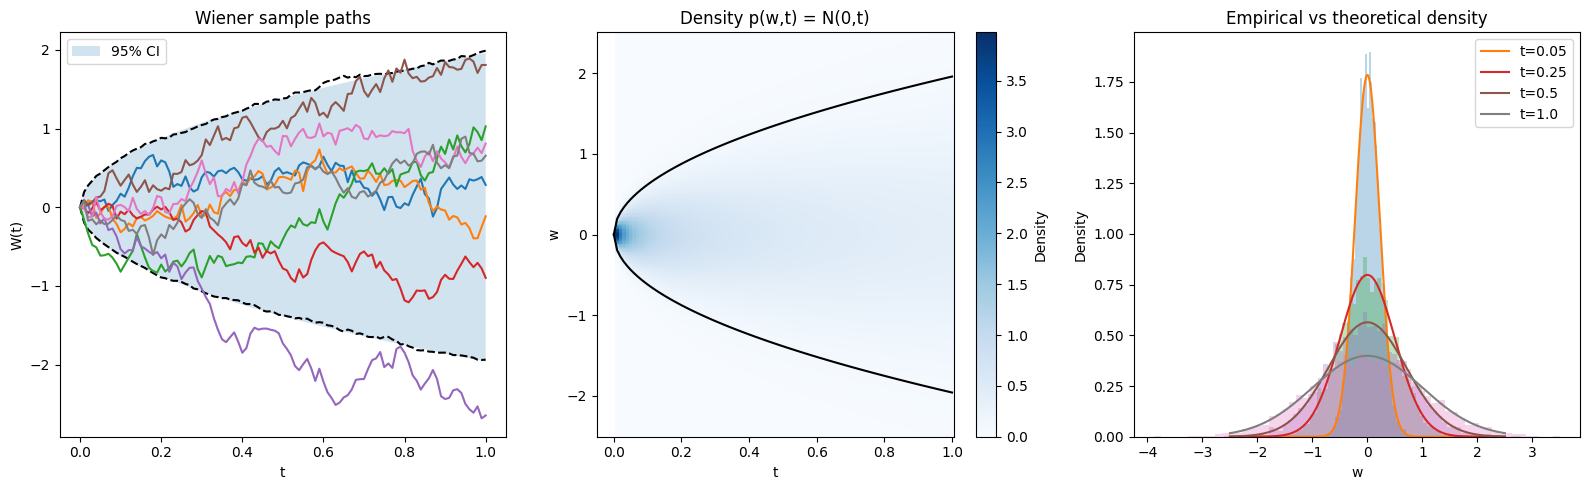

Max |mean|: 0.011396572925150394
Max |variance - t|: 0.01274716854095459
Final variance: 0.9974542260169983 Expected: 1.0


In [3]:
from jax.scipy.stats import norm

key = jax.random.PRNGKey(42)
T, N, S = 1.0, 100, 5000
dt = T / N
t = jnp.linspace(0, T, N + 1)


dW = jnp.sqrt(dt) * jax.random.normal(key, (S, N))
W = jnp.concatenate([jnp.zeros((S, 1)), jnp.cumsum(dW, axis=1)], axis=1)

ci = 1.96 * jnp.sqrt(t)
q_lo, q_hi = jnp.percentile(W, jnp.array([2.5, 97.5]), axis=0)
mean, var = W.mean(axis=0), W.var(axis=0)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))


ax = axes[0]
ax.fill_between(t, -ci, ci, alpha=0.2, label="95% CI")
ax.plot(t, q_lo, "k--", t, q_hi, "k--")
for i in range(8):
    ax.plot(t, W[i])
ax.set(title="Wiener sample paths", xlabel="t", ylabel="W(t)")
ax.legend()


w = jnp.linspace(-2.5, 2.5, 300)
tt, ww = jnp.meshgrid(t[1:], w)
im = axes[1].pcolormesh(tt, ww, norm.pdf(ww, 0, jnp.sqrt(tt)),
                         shading="auto", cmap="Blues")
axes[1].plot(t, ci, "k-", t, -ci, "k-")
axes[1].set(title="Density p(w,t) = N(0,t)", xlabel="t", ylabel="w")
fig.colorbar(im, ax=axes[1], label="Density")


for ts in [0.05, 0.25, 0.5, 1.0]:
    idx = round(ts / dt)
    axes[2].hist(W[:, idx], bins=60, density=True, alpha=0.3)
    axes[2].plot(w, norm.pdf(w, 0, jnp.sqrt(t[idx])),
                 label=f"t={ts}")
axes[2].set(title="Empirical vs theoretical density",
            xlabel="w", ylabel="Density")
axes[2].legend()

fig.tight_layout()
fig.savefig("wiener_process_jax.png", dpi=150)
plt.show()

# Sanity checks
print("Max |mean|:", float(jnp.abs(mean).max()))
print("Max |variance - t|:", float(jnp.abs(var - t).max()))
print("Final variance:", float(var[-1]), "Expected:", T)


# Exercise 2: Compound Poisson process (3 points)

Simulate the compound Poisson process under different intensities. Compare the processes using a Gaussian and Exponential jump size distribution and describe the processes you find.

## Solution 2

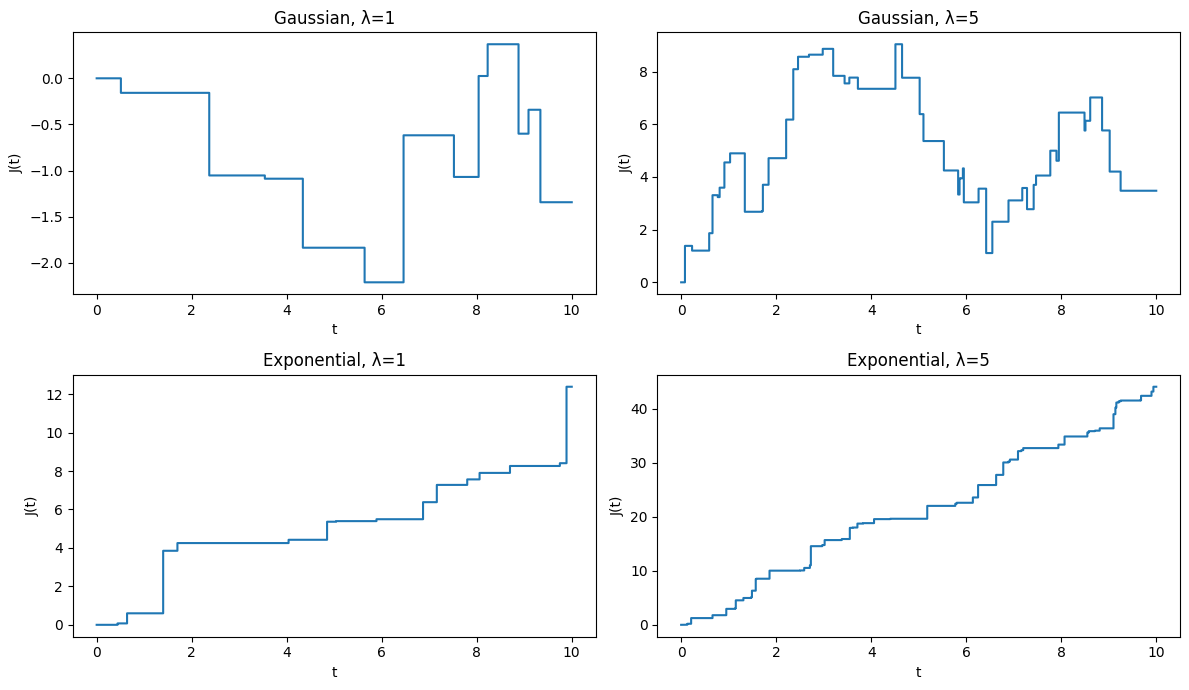

In [4]:

key = jax.random.PRNGKey(42)
T, N = 10, 1000
t = jnp.linspace(0, T, N + 1)
dt = T / N

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, lam, dist in [
    (axes[0, 0], 1, "Gaussian"),
    (axes[0, 1], 5, "Gaussian"),
    (axes[1, 0], 1, "Exponential"),
    (axes[1, 1], 5, "Exponential")
]:
    key, k1, k2 = jax.random.split(key, 3)
    counts = jax.random.poisson(k1, lam * dt, (N,))
    jumps = (jax.random.normal(k2, (N,)) if dist == "Gaussian"
             else jax.random.exponential(k2, (N,)))
    J = jnp.concatenate([jnp.zeros(1), jnp.cumsum(counts * jumps)])
    ax.step(t, J, where="post")
    ax.set(title=f"{dist}, λ={lam}", xlabel="t", ylabel="J(t)")

plt.tight_layout()
plt.show()


In [5]:
# Observations:
#  For higher intensity (λ = 5), jumps occur more frequently than in case of λ = 1.
#  The Gaussian jump could be either positive or negative; thus, the process goes both ways.
#  The exponential jump is always positive; thus, the process is non-decreasing.
#  Both processes remain constant in between random jumps.

# Exercise 3: Jump-diffusion process (5 points)

Simulate a stochastic harmonic oscillator, where the velocity is subjected to both a **Wiener process** and **jump processes**. Use a Gaussian jump distribution in the jump process. Choose the parameters such that the noise is visible but does not completely dominate the dynamics.

Generate an ensemble of trajectories. Plot a couple of trajectories of this ensemble and plot the confidence interval of the whole ensemble. Explain what happens with the confidence interval when you increase the number of samples in your ensemble.

## Solution 3

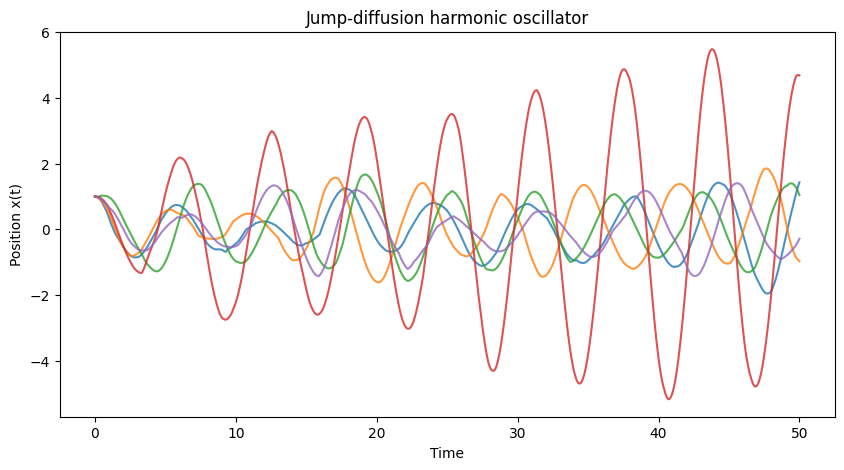

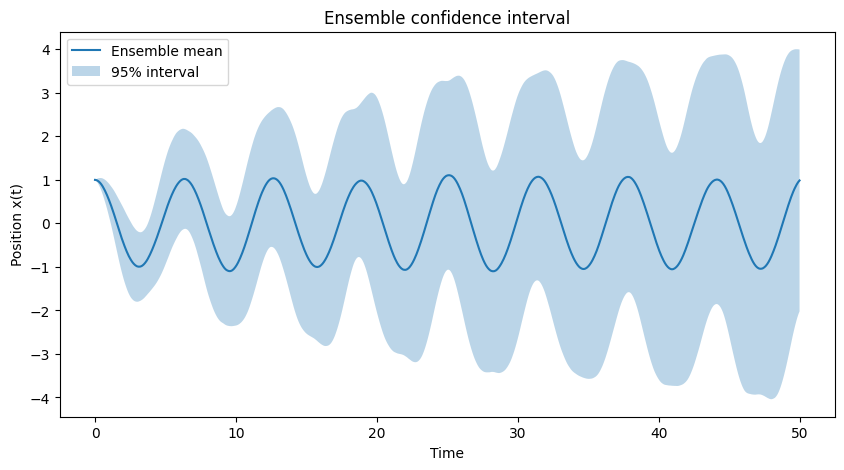

In [8]:

key = jax.random.PRNGKey(42)
T, N, M = 50, 1000, 100
dt = T / N
t = jnp.linspace(0, T, N + 1)

omega = 1.0
sigma = 0.15
lam = 1.0
jump_sigma = 0.3

key, k1, k2, k3 = jax.random.split(key, 4)
dW = jax.random.normal(k1, (M, N)) * jnp.sqrt(dt)
counts = jax.random.poisson(k2, lam * dt, (M, N))
jumps = jax.random.normal(k3, (M, N)) * jump_sigma * counts

x = jnp.zeros((M, N + 1))
v = jnp.zeros((M, N + 1))
x = x.at[:, 0].set(1.0)

for i in range(N):
    v = v.at[:, i + 1].set(
        v[:, i] - omega**2 * x[:, i] * dt
        + sigma * dW[:, i] + jumps[:, i]
    )
    x = x.at[:, i + 1].set(x[:, i] + v[:, i + 1] * dt)

# Plot a few trajectories
plt.figure(figsize=(10, 5))
for i in range(5):
    plt.plot(t, x[i], alpha=0.8)
plt.xlabel("Time")
plt.ylabel("Position x(t)")
plt.title("Jump-diffusion harmonic oscillator")
plt.show()

# Plot ensemble mean and confidence interval
mean = jnp.mean(x, axis=0)
std = jnp.std(x, axis=0)

plt.figure(figsize=(10, 5))
plt.plot(t, mean, label="Ensemble mean")
plt.fill_between(t, mean - 1.96 * std, mean + 1.96 * std,
                 alpha=0.3, label="95% interval")
plt.xlabel("Time")
plt.ylabel("Position x(t)")
plt.title("Ensemble confidence interval")
plt.legend()
plt.show()



*The* confidence interval becomes wider when the number of trajectories increases, but converges to +- 0.5.

In [9]:
# Observations:
# Wiener noise causes small, continuous random fluctuations in velocity.
# Gaussian jumps cause sudden changes in velocity at random times.
# Increasing the number of trajectories makes the estimated mean and
# confidence interval more stable; it does not necessarily make the
# confidence interval wider. The interval reflects trajectory variability,
# not the number of trajectories in the ensemble.